# A4 - Co-construction Detection

This notebook asks which moments of co-construction each method surfaces, and which it misses or misreads (RQ1).

We define co-construction as a turn coded **Other at Medium or High**: the student builds on a specific peer's idea and at least engages its details. Each method is turned into a yes/no flag per turn and compared with the adjudicated human codes.

- **Test sample:** OBS_26-0498, segments c and d.
- **Development check:** OBS_26-0515, segments a and b (used to calibrate the codebook, so not a clean test).

All inputs are code-only files in the repository (`results/analysis_table.csv`, `results/gca_merged_units_*.csv`, `Data/human_coding/`). Run it from the top of the repository. Outputs go to `results/co_construction/`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reuse the turn rule from the human IRR script.
sys.path.append("analysis")
from irr_semantic import build_turns

RESULTS_DIR = Path("results")
CODING_DIR = Path("Data/human_coding")
OUTPUT_DIR = RESULTS_DIR / "co_construction"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TEST = "OBS_26-0498"
DEVELOPMENT = "OBS_26-0515"
SAMPLE_LABELS = {TEST: "Test: OBS_26-0498 c-d", DEVELOPMENT: "Development: OBS_26-0515 a-b"}

CO_CONSTRUCTION_LEVELS = {"medium", "high"}
GCA_THRESHOLD = 0.75  # top quarter of units within the observation
NOT_CODED = {"", "n/a", "unclear", "unclear / not coded"}

## 1. Methods and flags

| Method | Flags a turn as co-construction when |
|---|---|
| Adjudicated human codes (reference) | Whose = Other and Level = Medium or High |
| Vishal, Caesar (test sample only) | the same, on each coder's normalized codes; a human benchmark |
| Enhanced LLM | Whose = Other and Level = Medium or High |
| Basic LLM | peer-engagement label = Medium or High (it has no Whose) |
| GCA responsivity | the turn's GCA unit is in the top quarter for responsivity: how similar it is to the previous few peer units |
| GCA social impact | the turn's GCA unit is in the top quarter for social impact: how similar the next few peer units are to it |

Responsivity looks backward from the responder, which matches what our Other code marks. Social impact looks forward from the source idea, and is the measure in our GCA baseline. Our human codes do not record *Builds on* for these segments, so we cannot check social impact on the source turns; both GCA measures are scored on the turn itself.

**Units.** Turns come from the adjudicated codes, using the IRR rule within each segment: a speaker's coded lines up to the line with a Level. Adult lines are dropped. Labels are lowercased, and blank, N/A, Unclear, and "Unclear / not coded" count as not coded. For each turn:

- Human coders: last Whose and last Level within the turn.
- Enhanced LLM: last Whose within the turn, and the Level of its own turn that contains the turn's last line (it writes Level only on the last line of its own turns).
- Basic LLM: last engagement label within the turn.
- GCA: the unit containing the turn's last line that has a unit. GCA keeps only Miguel and Gregorio, so turns by the student labeled "Other" have no score and are never flagged.

In [2]:
table = pd.read_csv(RESULTS_DIR / "analysis_table.csv", keep_default_na=False, dtype=str)
students = table[table["is_adult"] == "False"].copy()


def clean(label):
    label = str(label).strip().lower()
    return "" if label in NOT_CODED else label


def last_code(labels):
    labels = [label for label in labels if label]
    return labels[-1] if labels else ""


def segment_turns(raw):
    # Run build_turns per segment so turns never cross segments.
    turns = []
    for _, segment in raw.groupby(raw["row"].str[0], sort=False):
        segment = segment.reset_index(drop=True)
        turns += [list(segment.loc[turn, "row"]) for turn in build_turns(segment)]
    return turns


normalized_coders = {
    name: pd.read_csv(CODING_DIR / "normalized" / f"codes_OBS_26-0498_cd_{name}_normalized.csv",
                      keep_default_na=False, dtype=str).set_index("row")
    for name in ["Vishal", "Caesar"]
}

gca_units = pd.concat([
    pd.read_csv(RESULTS_DIR / f"gca_merged_units_{observation}.csv")
    for observation in [TEST, DEVELOPMENT]
], ignore_index=True)

In [3]:
def is_co_construction(whose, level):
    return whose == "other" and level in CO_CONSTRUCTION_LEVELS


def build_turn_table(observation):
    lines = students[students["observation"] == observation].reset_index(drop=True)
    final = lines.rename(columns={"human_final_whose": "whose", "human_final_level": "level"})
    by_row = lines.set_index("row")
    labels = {column: by_row[column].map(clean) for column in
              ["human_final_whose", "human_final_level", "basic_peer_engagement",
               "enhanced_whose", "enhanced_level"]}
    enhanced_turn_level = labels["enhanced_level"].groupby(by_row["enhanced_turn"]).agg(last_code)
    units = gca_units[gca_units["observation"] == observation].set_index("unit_id")

    records = []
    for rows in segment_turns(final[["row", "speaker", "whose", "level"]]):
        record = {
            "observation": observation,
            "turn": rows[0] if len(rows) == 1 else f"{rows[0]}-{rows[-1]}",
            "rows": " ".join(rows),
            "speaker": by_row.loc[rows[-1], "speaker"],
            "adjudicated_whose": last_code(labels["human_final_whose"][rows]),
            "adjudicated_level": last_code(labels["human_final_level"][rows]),
        }

        if observation == TEST:
            for name, codes in normalized_coders.items():
                record[f"{name.lower()}_whose"] = last_code(codes.loc[rows, "whose"].map(clean))
                record[f"{name.lower()}_level"] = last_code(codes.loc[rows, "level"].map(clean))

        turn_ids = [turn for turn in by_row.loc[rows, "enhanced_turn"] if turn]
        record["enhanced_whose"] = last_code(labels["enhanced_whose"][rows])
        record["enhanced_level"] = enhanced_turn_level[turn_ids[-1]] if turn_ids else ""
        record["basic_engagement"] = last_code(labels["basic_peer_engagement"][rows])

        unit_ids = [unit for unit in by_row.loc[rows, "gca_unit"] if unit]
        record["gca_unit"] = unit_ids[-1] if unit_ids else ""
        record["responsivity_pct"] = units.loc[unit_ids[-1], "responsivity_pct"] if unit_ids else np.nan
        record["social_impact_pct"] = units.loc[unit_ids[-1], "impact_pct"] if unit_ids else np.nan
        records.append(record)

    turns = pd.DataFrame(records)
    turns["Adjudicated"] = [is_co_construction(w, l) for w, l in zip(turns["adjudicated_whose"], turns["adjudicated_level"])]
    if observation == TEST:
        for name in ["Vishal", "Caesar"]:
            turns[name] = [is_co_construction(w, l) for w, l in
                           zip(turns[f"{name.lower()}_whose"], turns[f"{name.lower()}_level"])]
    turns["Enhanced LLM"] = [is_co_construction(w, l) for w, l in zip(turns["enhanced_whose"], turns["enhanced_level"])]
    turns["Basic LLM"] = turns["basic_engagement"].isin(CO_CONSTRUCTION_LEVELS)
    turns["GCA responsivity"] = turns["responsivity_pct"] >= GCA_THRESHOLD
    turns["GCA social impact"] = turns["social_impact_pct"] >= GCA_THRESHOLD
    return turns


turn_table = pd.concat([build_turn_table(TEST), build_turn_table(DEVELOPMENT)], ignore_index=True)
turn_table.to_csv(OUTPUT_DIR / "detection_turns.csv", index=False)

METHODS = ["Vishal", "Caesar", "Basic LLM", "Enhanced LLM", "GCA responsivity", "GCA social impact"]
turn_table[turn_table["observation"] == TEST][["turn", "speaker", "Adjudicated"] + METHODS]

,turn,speaker,Adjudicated,Vishal,Caesar,Basic LLM,Enhanced LLM,GCA responsivity,GCA social impact
0,c5,Other,False,False,False,True,False,False,False
1,c10,Gregorio,False,False,False,True,True,False,False
2,c11,Other,True,True,True,True,False,False,False
3,c12-c13,Gregorio,True,True,True,True,True,False,False
4,c14,Miguel,True,True,False,True,True,False,False
5,c15,Other,False,False,False,False,False,False,False
6,c16,Gregorio,False,True,False,True,True,False,False
7,c17,Other,False,True,False,True,True,False,False
8,c18,Miguel,True,True,True,True,True,False,False
9,c20,Other,False,False,False,False,False,False,False


## 2. Flags outside the human turns

A method can also flag lines that no human coded at all, which the turn table cannot show. We count these separately:

- LLMs: student lines outside every adjudicated turn that the method flags (Other at Medium or High for the enhanced prompt, engagement Medium or High for the basic prompt).
- GCA: units whose lines fall entirely outside the adjudicated turns and that reach the top quarter. GCA scores every unit in the observation, so only units in the coded segments are counted.

In [4]:
def outside_flags(observation):
    lines = students[students["observation"] == observation]
    in_turns = set(" ".join(turn_table.loc[turn_table["observation"] == observation, "rows"]).split())
    outside = lines[~lines["row"].isin(in_turns)]
    segments = set(lines["row"].str[0])

    enhanced = outside[[is_co_construction(clean(w), clean(l))
                        for w, l in zip(outside["enhanced_whose"], outside["enhanced_level"])]]
    basic = outside[outside["basic_peer_engagement"].map(clean).isin(CO_CONSTRUCTION_LEVELS)]

    units = gca_units[(gca_units["observation"] == observation) & gca_units["segment"].isin(segments)]
    units = units[[not set(rows.split()) & in_turns for rows in units["unit_rows"]]]

    return {
        "Basic LLM": list(basic["row"]),
        "Enhanced LLM": list(enhanced["row"]),
        "GCA responsivity": list(units.loc[units["responsivity_pct"] >= GCA_THRESHOLD, "unit_rows"]),
        "GCA social impact": list(units.loc[units["impact_pct"] >= GCA_THRESHOLD, "unit_rows"]),
    }


outside = {observation: outside_flags(observation) for observation in [TEST, DEVELOPMENT]}
pd.DataFrame([
    {"observation": observation, "method": method, "count": len(found), "lines or units": ", ".join(found)}
    for observation, methods in outside.items() for method, found in methods.items()
])

,observation,method,count,lines or units
0,OBS_26-0498,Basic LLM,5,"c2, c3, c4, c9, c37"
1,OBS_26-0498,Enhanced LLM,0,
2,OBS_26-0498,GCA responsivity,0,
3,OBS_26-0498,GCA social impact,1,d35 d36
4,OBS_26-0515,Basic LLM,12,"a5, a13, a20, a61, a65, a68, a70, a82, b52, b5..."
5,OBS_26-0515,Enhanced LLM,0,
6,OBS_26-0515,GCA responsivity,3,"a65, b4, b66"
7,OBS_26-0515,GCA social impact,0,


## 3. Detection summary

For each method, against the adjudicated co-construction turns:

- **Recall**: how many of the adjudicated co-construction turns the method flags.
- **Precision**: of the coded turns the method flags, how many the adjudicated codes call co-construction.
- **Flags outside coded turns**: from section 2; these are not counted in precision, because the humans did not judge those lines.

In [5]:
def fraction(matches, n):
    return f"{matches}/{n} ({matches / n:.0%})" if n else "0/0"


def detection_summary(turns, outside_by_method, methods):
    reference = turns["Adjudicated"]
    rows = []
    for method in methods:
        flagged = turns[method]
        hits = int((flagged & reference).sum())
        rows.append({
            "Method": method,
            "Turns flagged": int(flagged.sum()),
            "Recall": fraction(hits, int(reference.sum())),
            "Precision": fraction(hits, int(flagged.sum())),
            "Flags outside coded turns": len(outside_by_method.get(method, [])),
            "recall_value": hits / reference.sum() if reference.sum() else np.nan,
            "precision_value": hits / flagged.sum() if flagged.sum() else np.nan,
        })
    return pd.DataFrame(rows)


summaries = []
for observation in [TEST, DEVELOPMENT]:
    turns = turn_table[turn_table["observation"] == observation]
    methods = METHODS if observation == TEST else METHODS[2:]
    summary = detection_summary(turns, outside[observation], methods)
    summary.insert(0, "Sample", SAMPLE_LABELS[observation])
    summary.insert(2, "Reference turns", int(turns["Adjudicated"].sum()))
    summaries.append(summary)

summary = pd.concat(summaries, ignore_index=True)
summary.to_csv(OUTPUT_DIR / "detection_summary.csv", index=False)
summary_table = summary.drop(columns=["recall_value", "precision_value"])
summary_table

,Sample,Method,Reference turns,Turns flagged,Recall,Precision,Flags outside coded turns
0,Test: OBS_26-0498 c-d,Vishal,6,10,6/6 (100%),6/10 (60%),0
1,Test: OBS_26-0498 c-d,Caesar,6,4,4/6 (67%),4/4 (100%),0
2,Test: OBS_26-0498 c-d,Basic LLM,6,17,5/6 (83%),5/17 (29%),5
3,Test: OBS_26-0498 c-d,Enhanced LLM,6,8,4/6 (67%),4/8 (50%),0
4,Test: OBS_26-0498 c-d,GCA responsivity,6,2,0/6 (0%),0/2 (0%),0
5,Test: OBS_26-0498 c-d,GCA social impact,6,0,0/6 (0%),0/0,1
6,Development: OBS_26-0515 a-b,Basic LLM,5,23,5/5 (100%),5/23 (22%),12
7,Development: OBS_26-0515 a-b,Enhanced LLM,5,5,2/5 (40%),2/5 (40%),0
8,Development: OBS_26-0515 a-b,GCA responsivity,5,18,2/5 (40%),2/18 (11%),3
9,Development: OBS_26-0515 a-b,GCA social impact,5,9,3/5 (60%),3/9 (33%),0


In [6]:
def save_table_image(frame, path, title, font_size=9):
    figure, axis = plt.subplots(figsize=(4, 0.3 * (len(frame) + 2)))
    axis.axis("off")
    shown = axis.table(
        cellText=frame.astype(str).values,
        colLabels=frame.columns,
        cellLoc="left",
        colLoc="left",
        loc="upper left",
    )
    shown.auto_set_font_size(False)
    shown.set_fontsize(font_size)
    shown.auto_set_column_width(list(range(frame.shape[1])))
    shown.scale(1, 1.4)
    for (row, column), cell in shown.get_celld().items():
        cell.set_edgecolor("#d0d0d0")
        if row == 0:
            cell.set_facecolor("#eef2f7")
            cell.set_text_props(weight="bold")
    axis.set_title(title, loc="left", fontsize=11, weight="bold")
    figure.savefig(path, dpi=200, bbox_inches="tight")
    plt.close(figure)


save_table_image(summary_table, OUTPUT_DIR / "detection_summary.png",
                 "Co-construction (Other at Medium or High): detection by method")

## 4. Which turns each method surfaces

Test sample. Rows are every turn that the adjudicated codes or any method flags. Each cell shows the method's label for that turn (for GCA, the unit's percentile):

- **Dark blue**: agrees with the adjudicated codes that this is co-construction (hit).
- **Light red**: an adjudicated co-construction turn the method does not flag (miss).
- **Orange**: flagged by the method but not by the adjudicated codes (extra).

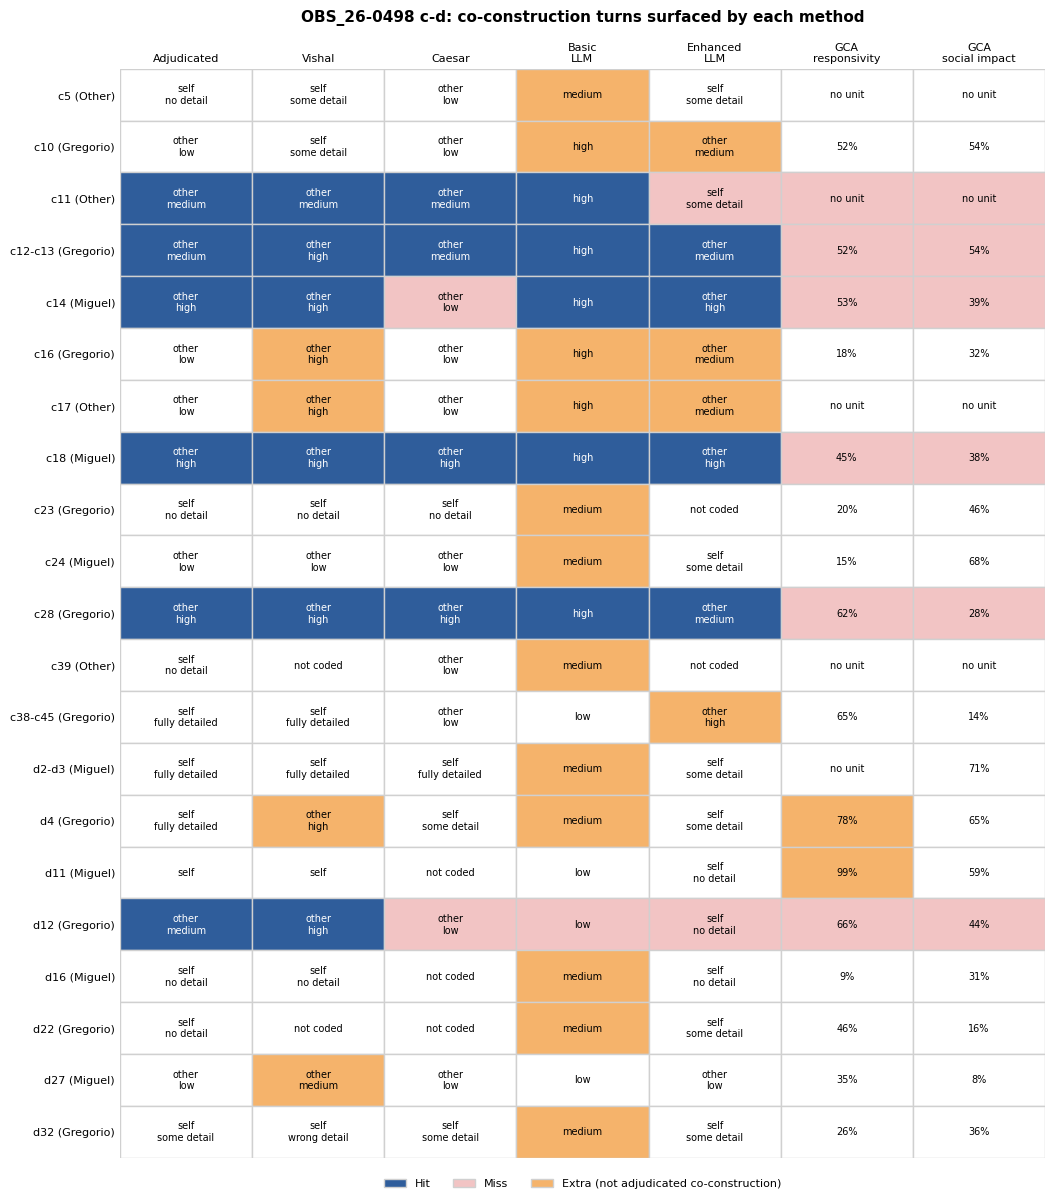

In [7]:
def cell_label(turn, method):
    if method in ["Adjudicated", "Vishal", "Caesar", "Enhanced LLM"]:
        prefix = {"Adjudicated": "adjudicated", "Vishal": "vishal", "Caesar": "caesar", "Enhanced LLM": "enhanced"}[method]
        whose, level = turn[f"{prefix}_whose"], turn[f"{prefix}_level"]
        return f"{whose}\n{level}" if whose and level else (whose or "not coded")
    if method == "Basic LLM":
        return turn["basic_engagement"] or "not coded"
    column = "responsivity_pct" if method == "GCA responsivity" else "social_impact_pct"
    return "no unit" if pd.isna(turn[column]) else f"{turn[column]:.0%}"


test_turns = turn_table[turn_table["observation"] == TEST]
shown = test_turns[test_turns[["Adjudicated"] + METHODS].any(axis=1)].reset_index(drop=True)
columns = ["Adjudicated"] + METHODS
colors = {"hit": "#2f5d9b", "miss": "#f2c4c4", "extra": "#f5b36b", "none": "#ffffff"}

figure, axis = plt.subplots(figsize=(1.35 * len(columns) + 1.2, 0.52 * len(shown) + 1.2))
for i, turn in shown.iterrows():
    for j, method in enumerate(columns):
        if turn["Adjudicated"]:
            state = "hit" if turn[method] else "miss"
        else:
            state = "extra" if turn[method] else "none"
        axis.add_patch(plt.Rectangle((j, i), 1, 1, facecolor=colors[state], edgecolor="#d0d0d0"))
        axis.text(j + 0.5, i + 0.5, cell_label(turn, method), ha="center", va="center", fontsize=7,
                  color="white" if state == "hit" else "black")

axis.set_xlim(0, len(columns))
axis.set_ylim(len(shown), 0)
axis.set_xticks([j + 0.5 for j in range(len(columns))])
axis.set_xticklabels([column.replace(" ", "\n", 1) for column in columns], fontsize=8)
axis.xaxis.tick_top()
axis.set_yticks([i + 0.5 for i in range(len(shown))])
axis.set_yticklabels([f"{turn} ({speaker})" for turn, speaker in zip(shown["turn"], shown["speaker"])], fontsize=8)
axis.tick_params(length=0)
for spine in axis.spines.values():
    spine.set_visible(False)

handles = [plt.Rectangle((0, 0), 1, 1, facecolor=colors[state], edgecolor="#d0d0d0") for state in ["hit", "miss", "extra"]]
axis.legend(handles, ["Hit", "Miss", "Extra (not adjudicated co-construction)"],
            loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=3, frameon=False, fontsize=8)
axis.set_title("OBS_26-0498 c-d: co-construction turns surfaced by each method", fontsize=11, weight="bold", pad=34)
figure.tight_layout()
figure.savefig(OUTPUT_DIR / "detection_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Misses and misreads

Each miss or extra flag is classified by what the method got wrong:

- **Whose**: the method read a peer-building turn as Self, or a Self turn as building on a peer.
- **Level**: Whose agrees but the level is on the wrong side of Medium (a Low turn raised, or a Medium or High turn lowered).
- **Not coded**: the method left the turn uncoded.
- **Not scored**: GCA has no unit for the turn (the student labeled "Other" is excluded).
- **Below threshold** / **Above threshold**: the GCA percentile is under or over the top quarter.

In [8]:
def classify(turn, method):
    adjudicated = turn["Adjudicated"]
    if method in ["Vishal", "Caesar", "Enhanced LLM"]:
        prefix = {"Vishal": "vishal", "Caesar": "caesar", "Enhanced LLM": "enhanced"}[method]
        whose, level = turn[f"{prefix}_whose"], turn[f"{prefix}_level"]
        if not whose:
            return "Not coded"
        if whose != turn["adjudicated_whose"]:
            return "Whose"
        return "Level"
    if method == "Basic LLM":
        if not turn["basic_engagement"]:
            return "Not coded"
        if not adjudicated and turn["adjudicated_whose"] == "self":
            return "Whose"
        return "Level"
    column = "responsivity_pct" if method == "GCA responsivity" else "social_impact_pct"
    if pd.isna(turn[column]):
        return "Not scored"
    return "Below threshold" if adjudicated else "Above threshold"


error_rows = []
for observation in [TEST, DEVELOPMENT]:
    turns = turn_table[turn_table["observation"] == observation]
    methods = METHODS if observation == TEST else METHODS[2:]
    for _, turn in turns.iterrows():
        for method in methods:
            if turn[method] == turn["Adjudicated"]:
                continue
            error_rows.append({
                "Sample": SAMPLE_LABELS[observation],
                "Method": method,
                "Turn": turn["turn"],
                "Speaker": turn["speaker"],
                "Error": "Miss" if turn["Adjudicated"] else "Extra",
                "Adjudicated": cell_label(turn, "Adjudicated").replace("\n", " / "),
                "Method label": cell_label(turn, method).replace("\n", " / "),
                "Reason": classify(turn, method),
            })

errors = pd.DataFrame(error_rows)
errors.to_csv(OUTPUT_DIR / "misses_and_misreads.csv", index=False)

error_counts = (
    errors.groupby(["Sample", "Method", "Error", "Reason"], sort=False).size()
    .rename("Turns").reset_index()
)
error_counts.to_csv(OUTPUT_DIR / "misses_and_misreads_counts.csv", index=False)

test_errors = errors[(errors["Sample"] == SAMPLE_LABELS[TEST]) & errors["Method"].isin(["Basic LLM", "Enhanced LLM", "GCA responsivity", "GCA social impact"])]
save_table_image(test_errors.drop(columns="Sample"), OUTPUT_DIR / "misses_and_misreads.png",
                 "OBS_26-0498 c-d: misses and extra flags, LLMs and GCA vs adjudicated co-construction")
error_counts

,Sample,Method,Error,Reason,Turns
0,Test: OBS_26-0498 c-d,Basic LLM,Extra,Whose,8
1,Test: OBS_26-0498 c-d,Basic LLM,Extra,Level,4
2,Test: OBS_26-0498 c-d,Enhanced LLM,Extra,Level,3
3,Test: OBS_26-0498 c-d,Enhanced LLM,Miss,Whose,2
4,Test: OBS_26-0498 c-d,GCA responsivity,Miss,Not scored,1
5,Test: OBS_26-0498 c-d,GCA social impact,Miss,Not scored,1
6,Test: OBS_26-0498 c-d,GCA responsivity,Miss,Below threshold,5
7,Test: OBS_26-0498 c-d,GCA social impact,Miss,Below threshold,5
8,Test: OBS_26-0498 c-d,Caesar,Miss,Level,2
9,Test: OBS_26-0498 c-d,Vishal,Extra,Level,3


## 6. GCA scores by human category

Does semantic similarity rise with uptake, or with repetition? Each point is a GCA unit in the test segments (Miguel and Gregorio only), placed by the adjudicated category of the turn that contains its lines. Units with no adjudicated code are shown separately. The dashed line marks the top-quarter threshold.

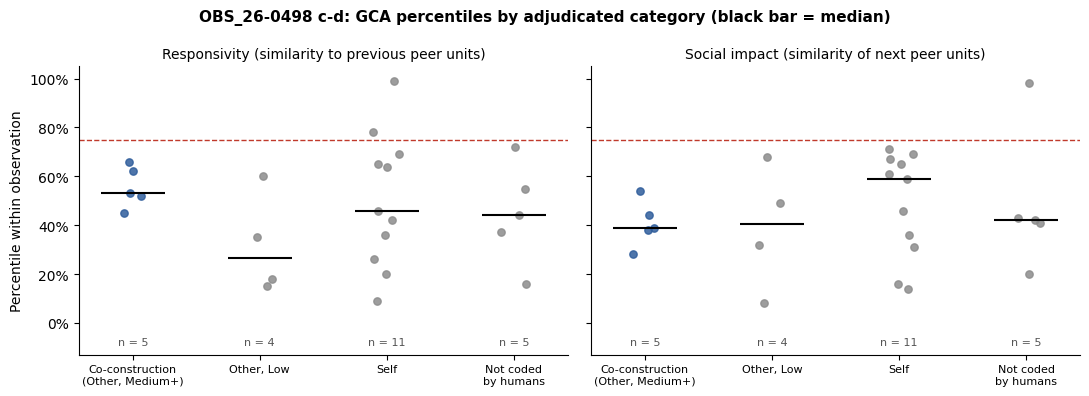

,responsivity_pct,impact_pct
category,,
"Co-construction\n(Other, Medium+)",0.530,0.390
"Other, Low",0.265,0.405
Self,0.460,0.590
Not coded\nby humans,0.440,0.420


In [9]:
CATEGORY_ORDER = ["Co-construction\n(Other, Medium+)", "Other, Low", "Self", "Not coded\nby humans"]


def turn_category(whose, level):
    if is_co_construction(whose, level):
        return CATEGORY_ORDER[0]
    if whose == "other":
        return CATEGORY_ORDER[1]
    if whose == "self":
        return CATEGORY_ORDER[2]
    return CATEGORY_ORDER[3]


row_category = {}
for _, turn in test_turns.iterrows():
    for row in turn["rows"].split():
        row_category[row] = turn_category(turn["adjudicated_whose"], turn["adjudicated_level"])

test_units = gca_units[(gca_units["observation"] == TEST) & gca_units["segment"].isin(["c", "d"])].copy()


def unit_category(rows):
    found = [row_category[row] for row in rows.split() if row in row_category]
    return min(found, key=CATEGORY_ORDER.index) if found else CATEGORY_ORDER[3]


test_units["category"] = test_units["unit_rows"].map(unit_category)
test_units.to_csv(OUTPUT_DIR / "gca_units_by_category.csv", index=False)

figure, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
rng = np.random.default_rng(435)
for axis, (column, title) in zip(axes, [("responsivity_pct", "Responsivity (similarity to previous peer units)"),
                                         ("impact_pct", "Social impact (similarity of next peer units)")]):
    for position, category in enumerate(CATEGORY_ORDER):
        values = test_units.loc[test_units["category"] == category, column].dropna()
        x = position + rng.uniform(-0.12, 0.12, len(values))
        axis.scatter(x, values, s=28, color="#2f5d9b" if position == 0 else "#8c8c8c", alpha=0.85, zorder=3)
        if len(values):
            axis.hlines(values.median(), position - 0.25, position + 0.25, color="black", linewidth=1.5, zorder=4)
        axis.text(position, -0.09, f"n = {len(values)}", ha="center", fontsize=8, color="#555555")
    axis.axhline(GCA_THRESHOLD, color="#c0392b", linestyle="--", linewidth=1)
    axis.set_xticks(range(len(CATEGORY_ORDER)))
    axis.set_xticklabels(CATEGORY_ORDER, fontsize=8)
    axis.set_ylim(-0.13, 1.05)
    axis.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}" if value >= 0 else ""))
    axis.set_title(title, fontsize=10)
    axis.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Percentile within observation")
figure.suptitle("OBS_26-0498 c-d: GCA percentiles by adjudicated category (black bar = median)", fontsize=11, weight="bold")
figure.tight_layout()
figure.savefig(OUTPUT_DIR / "gca_by_category.png", dpi=200, bbox_inches="tight")
plt.show()

test_units.groupby("category")[["responsivity_pct", "impact_pct"]].median().reindex(CATEGORY_ORDER)

## 7. Sensitivity checks

How much do the results depend on our choices? Recall and precision on the test sample under:

- the main definition (Other at Medium or High) and a stricter one (Other at High only);
- GCA thresholds at the top quarter and the top half.

Outside flags are left out here; they follow the same pattern as section 2.

In [10]:
def flags_under(turns, levels, gca_threshold):
    flags = pd.DataFrame(index=turns.index)
    flags["Adjudicated"] = (turns["adjudicated_whose"] == "other") & turns["adjudicated_level"].isin(levels)
    for name in ["Vishal", "Caesar"]:
        flags[name] = (turns[f"{name.lower()}_whose"] == "other") & turns[f"{name.lower()}_level"].isin(levels)
    flags["Enhanced LLM"] = (turns["enhanced_whose"] == "other") & turns["enhanced_level"].isin(levels)
    flags["Basic LLM"] = turns["basic_engagement"].isin(levels)
    flags["GCA responsivity"] = turns["responsivity_pct"] >= gca_threshold
    flags["GCA social impact"] = turns["social_impact_pct"] >= gca_threshold
    return flags


sensitivity_rows = []
for definition, levels in [("Other at Medium or High", {"medium", "high"}), ("Other at High only", {"high"})]:
    for gca_threshold in [0.75, 0.5]:
        flags = flags_under(test_turns, levels, gca_threshold)
        reference = flags["Adjudicated"]
        for method in METHODS:
            # The GCA threshold only changes the GCA rows.
            if not method.startswith("GCA") and gca_threshold != 0.75:
                continue
            hits = int((flags[method] & reference).sum())
            sensitivity_rows.append({
                "Definition": definition,
                "GCA threshold": f"top {1 - gca_threshold:.0%}" if method.startswith("GCA") else "",
                "Method": method,
                "Reference turns": int(reference.sum()),
                "Turns flagged": int(flags[method].sum()),
                "Recall": fraction(hits, int(reference.sum())),
                "Precision": fraction(hits, int(flags[method].sum())),
            })

sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity.to_csv(OUTPUT_DIR / "sensitivity.csv", index=False)
save_table_image(sensitivity, OUTPUT_DIR / "sensitivity.png", "OBS_26-0498 c-d: sensitivity of detection to definitions")
sensitivity

,Definition,GCA threshold,Method,Reference turns,Turns flagged,Recall,Precision
0,Other at Medium or High,,Vishal,6,10,6/6 (100%),6/10 (60%)
1,Other at Medium or High,,Caesar,6,4,4/6 (67%),4/4 (100%)
2,Other at Medium or High,,Basic LLM,6,17,5/6 (83%),5/17 (29%)
3,Other at Medium or High,,Enhanced LLM,6,8,4/6 (67%),4/8 (50%)
4,Other at Medium or High,top 25%,GCA responsivity,6,2,0/6 (0%),0/2 (0%)
5,Other at Medium or High,top 25%,GCA social impact,6,0,0/6 (0%),0/0
6,Other at Medium or High,top 50%,GCA responsivity,6,11,4/6 (67%),4/11 (36%)
7,Other at Medium or High,top 50%,GCA social impact,6,10,1/6 (17%),1/10 (10%)
8,Other at High only,,Vishal,3,8,3/3 (100%),3/8 (38%)
9,Other at High only,,Caesar,3,2,2/3 (67%),2/2 (100%)


## Outputs

All files are in `results/co_construction/` and contain codes and scores only, no transcript text.

| File | Contents |
|---|---|
| `detection_turns.csv` | Every adjudicated turn with each method's labels, GCA percentiles, and co-construction flags |
| `detection_summary.csv`, `.png` | Recall, precision, and outside flags by method |
| `detection_matrix.png` | Which co-construction turns each method surfaces, test sample |
| `misses_and_misreads.csv`, `.png`, `misses_and_misreads_counts.csv` | Every miss and extra flag with its reason |
| `gca_units_by_category.csv`, `gca_by_category.png` | GCA percentiles by adjudicated category |
| `sensitivity.csv`, `.png` | Results under a stricter definition and a looser GCA threshold |